# Deep BSDE Pricing and Basket Greeks

This study compares two neural formulations on synthetic European calls under
correlated geometric Brownian motion. The comparisons cover initial price and
spot risk, the time grid and basket dimension, and the cost of reusing a frozen
control for Monte Carlo pricing.

The executed notebook reads the retained Apple silicon results and recomputes
small numerical checks with the same package routines. The locked fit and
estimator results have their own reserved streams. The demonstrations below
use separate seeds and allocations.

1. [Model and independent references](#1.-Model-and-independent-references)
2. [Discounted BSDE and training objectives](#2.-Discounted-BSDE-and-training-objectives)
3. [Accuracy, dimension and time grid](#3.-Accuracy,-dimension-and-time-grid)
4. [Variance reduction and matched cost](#4.-Variance-reduction-and-matched-cost)
5. [Findings and scope](#5.-Findings-and-scope)

[Research report](../docs/report.md) · [Design](../experiments/design.json) ·
[Result data](../experiments/results.json)

In [1]:
import json
import sys
from collections import Counter
from pathlib import Path
from statistics import median

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
from matplotlib.ticker import FuncFormatter

root = Path.cwd().resolve()
if root.name == "notebooks":
    root = root.parent
if not (root / "experiments/design.json").is_file():
    raise FileNotFoundError("Start the kernel from the repository root or notebooks directory.")
sys.path.insert(0, str(root))

from bsde_pricing.black_scholes import BlackScholesReference
from bsde_pricing.experiment_design import ExperimentDesign
from bsde_pricing.finite_difference import FiniteDifferencePricer
from bsde_pricing.geometric_basket import GeometricBasketReference
from bsde_pricing.martingale import run_known_control_study
from bsde_pricing.monte_carlo import MonteCarloPricer

design = ExperimentDesign.load(root / "experiments/design.json")
spec = design.data
results = json.loads((root / "experiments/results.json").read_text())
if results["specification_sha256"] != design.sha256 or not results["complete"]:
    raise ValueError("The retained results must be complete and match the locked design.")

fits = results["fits"]
references = results["references"]
cohorts = results["estimators"]
formulations = {"value_gradient": "Value-gradient", "terminal_loss": "Terminal loss"}
colors = {"value_gradient": "#146B87", "terminal_loss": "#BA5738"}


def table(headers, rows):
    lines = [headers, ["---"] * len(headers), *rows]
    display(Markdown("\n".join("| " + " | ".join(map(str, row)) + " |" for row in lines)))


table(("Recorded run", "Value"), (
    ("Platform", results["runtime"]["system"]),
    ("Python / PyTorch", f"{results['runtime']['python']} / {results['runtime']['torch']}"),
    ("Training seeds", ", ".join(map(str, spec["final_training_seeds"]))),
    ("Fits completed", f"{sum(row['status'] == 'completed' for row in fits)} / {len(fits)}"),
    ("Estimator repetitions", sum(c["status_counts"].get("completed", 0) for c in cohorts.values())),
    ("Worker time", f"{results['elapsed_seconds']/60:.2f} minutes"),
    ("Raw report SHA-256", results["report_sha256"]),
))

| Recorded run | Value |
| --- | --- |
| Platform | macOS-27.0.1-arm64-arm-64bit |
| Python / PyTorch | 3.12.16 / 2.15.0 |
| Training seeds | 41001, 41002, 41003 |
| Fits completed | 78 / 78 |
| Estimator repetitions | 48 |
| Worker time | 33.12 minutes |
| Raw report SHA-256 | 3925218c01c755404d78ee22b556a5d2689795615526e0d22d1cb95597080819 |

## 1. Model and independent references

### Risk-neutral model

With $d$ assets, the correlation matrix has Cholesky factor $L$ satisfying
$LL^\top=\rho$. The $d$ components of $W$ are independent. At a spot vector
$s$, the drift is $b_i(s)=(r-q_i)s_i$ and the diffusion matrix is
$\Sigma(s)=\operatorname{diag}(s_i\sigma_i)L$. Rates and yields compound
continuously. Time is in years and volatilities are annualized.

$$
S_{t+h}^i=S_t^i\exp\left[(r-q_i-\tfrac12\sigma_i^2)h
                         +\sigma_i(L\Delta W)_i\right],
\qquad \Delta W\sim N(0,hI).
$$

For $g(s)=(B(s)-K)^+$ with positive weights summing to one, the risk-neutral
price is $u(t,s)=e^{-r(T-t)}\mathbb E[g(S_T)\mid S_t=s]$. The basket is
either $B(s)=\sum_iw_is_i$ or $B(s)=\prod_i s_i^{w_i}$. Terminal-payoff
references use one exact transition. The learned controls use intermediate
states to evaluate stochastic sums.

### Vanilla price, delta and gamma

For remaining time $\tau$, the Black–Scholes call is
$C=S e^{-q\tau}\Phi(d_1)-K e^{-r\tau}\Phi(d_2)$ with
$d_1=[\log(S/K)+(r-q+\sigma^2/2)\tau]/(\sigma\sqrt\tau)$ and
$d_2=d_1-\sigma\sqrt\tau$. Differentiation gives
$\Delta=e^{-q\tau}\Phi(d_1)$ and
$\Gamma=e^{-q\tau}\phi(d_1)/(S\sigma\sqrt\tau)$.

The Monte Carlo check uses exact terminal sampling. For the PDE check,
Crank–Nicolson advances backward from the payoff. Backward-Euler half steps
at startup damp oscillations near the kink. The large-spot boundary uses
the discounted intrinsic asymptote. Refining both grids at fixed $S_{\max}$
checks price and both derivatives.

In [2]:
vanilla = design.case("vanilla")
spot = vanilla.initial_spots[0]
analytical = BlackScholesReference(vanilla.model, vanilla.contract).evaluate(spot)
mc = MonteCarloPricer(vanilla.model, vanilla.contract)
mc_price = mc.estimate(vanilla.initial_spots, n_paths=65_536, rng=np.random.default_rng(2026))
mc_delta = mc.estimate_delta(vanilla.initial_spots, n_paths=65_536,
                             rng=np.random.default_rng(2026), bump_fraction=0.001)
table(("Quantity", "Black–Scholes", "Monte Carlo", "MC standard error"), (
    ("Price", f"{analytical.call_price:.6f}", f"{mc_price.price_estimate:.6f}", f"{mc_price.standard_error:.6f}"),
    ("Delta", f"{analytical.call_delta:.6f}", f"{mc_delta.pathwise.estimate:.6f}", f"{mc_delta.pathwise.standard_error:.6f}"),
    ("Gamma", f"{analytical.gamma:.6f}", "—", "—"),
))

fd = FiniteDifferencePricer(vanilla.model, vanilla.contract)
rows = []
for intervals in (100, 200, 400, 800):
    approximation = fd.solve(s_max=400, n_space=intervals, n_time=intervals).evaluate(spot)
    rows.append((intervals, f"{approximation.call_price-analytical.call_price:+.3e}",
                 f"{approximation.call_delta-analytical.call_delta:+.3e}",
                 f"{approximation.gamma-analytical.gamma:+.3e}"))
table(("FD intervals per axis", "Signed price error", "Signed delta error", "Signed gamma error"), rows)

| Quantity | Black–Scholes | Monte Carlo | MC standard error |
| --- | --- | --- | --- |
| Price | 9.413403 | 9.415953 | 0.054937 |
| Delta | 0.598706 | 0.600217 | 0.002285 |
| Gamma | 0.019333 | — | — |

| FD intervals per axis | Signed price error | Signed delta error | Signed gamma error |
| --- | --- | --- | --- |
| 100 | -3.953e-02 | -8.753e-04 | +1.115e-04 |
| 200 | -9.827e-03 | -2.169e-04 | +2.741e-05 |
| 400 | -2.453e-03 | -5.409e-05 | +6.825e-06 |
| 800 | -6.131e-04 | -1.352e-05 | +1.705e-06 |

The terminal Monte Carlo errors are consistent with the reported sampling
precision. Doubling both PDE resolutions cuts the three errors to roughly
one-quarter at the initial spot on these grids. The fixed domain and joint
refinement limit what this check says about the separate time, space and
boundary errors.

### Geometric and arithmetic basket references

Let $G=\prod_i s_i^{w_i}$, $a_i=w_i\sigma_i$,
$v=a^\top\rho a$ and $m=\sum_i w_i(r-q_i-\sigma_i^2/2)$. The conditional
log geometric return has mean $m\tau$ and variance $v\tau$. The scalar
Black–Scholes formula uses volatility $\sqrt v$ and effective yield
$q_{\rm eff}=r-m-v/2$. Its spot delta in coordinate $i$ follows by the chain
rule, $\Delta_i=C_G w_iG/s_i$.

For an arithmetic call, exact transitions give $\partial S_T^i/\partial
s_i=S_T^i/s_i$. With positive remaining variance, the strike event has zero
probability and an integrable lognormal factor dominates the derivative.
Consequently

$$
\Delta_i=e^{-r\tau}\mathbb E\left[
\mathbf 1_{\{B(S_T)>K\}} w_i S_T^i/s_i \mid S_t=s
\right].
$$

The price and each delta contribution are adjusted by a geometric control
with a known expectation. A coefficient estimated on independent pilot
draws preserves the mean of the adjusted evaluation sample. The antithetic
check uses independent pair averages. For randomized Sobol, the uncertainty
unit is an independent scramble mean. With $R=16$ scrambles the reference
uses a Student-$t$ interval with $R-1$ degrees of freedom. These are
approximate pointwise intervals.

The locked arithmetic reference qualifies when the price half-width and
each half-width divided by the asset weight are at most 0.002. Every
price and delta difference between the independent methods must also be
within four combined standard errors. The first allocation uses $2^{16}$
states per scramble and 131,072 independent antithetic pairs.

In [3]:
geometric = design.case("geometric-five")
geo_ref = GeometricBasketReference(geometric.model, geometric.contract).evaluate(geometric.initial_spots)
geo_mc = MonteCarloPricer(geometric.model, geometric.contract)
rows = []
for i, exact_delta in enumerate(geo_ref.call_deltas):
    check = geo_mc.estimate_coordinate_delta(geometric.initial_spots, coordinate=i,
                                             n_paths=65_536, rng=np.random.default_rng(2026))
    rows.append((i + 1, f"{exact_delta:.6f}", f"{check.pathwise.estimate:.6f}",
                 f"{check.central_bump.estimate:.6f}", f"{check.pathwise.standard_error:.6f}"))
table(("Asset", "Exact delta", "Pathwise delta", "Paired bump", "Pathwise SE"), rows)

rows = []
for case in spec["cases"]:
    name = case["name"]
    ref = references[name]
    rows.append((name, f"{ref['price']['estimate']:.8f}",
                 f"{ref.get('price_half_width', 0):.6f}",
                 f"{ref.get('max_scaled_delta_half_width', 0):.6f}",
                 f"{ref['max_combined_se_gap']:.2f}" if "max_combined_se_gap" in ref else "—",
                 ref["status"]))
table(("Contract", "Reference price", "Price half-width", "Max scaled-delta half-width",
       "Max gap / combined SE", "Status"), rows)

| Asset | Exact delta | Pathwise delta | Paired bump | Pathwise SE |
| --- | --- | --- | --- | --- |
| 1 | 0.057186 | 0.057379 | 0.057381 | 0.000237 |
| 2 | 0.077201 | 0.077462 | 0.077464 | 0.000320 |
| 3 | 0.093577 | 0.093893 | 0.093895 | 0.000388 |
| 4 | 0.135441 | 0.135898 | 0.135898 | 0.000562 |
| 5 | 0.147050 | 0.147546 | 0.147544 | 0.000610 |

| Contract | Reference price | Price half-width | Max scaled-delta half-width | Max gap / combined SE | Status |
| --- | --- | --- | --- | --- | --- |
| vanilla | 9.41340338 | 0.000000 | 0.000000 | — | exact |
| geometric-five | 5.49471932 | 0.000000 | 0.000000 | — | exact |
| arithmetic-10 | 6.40618543 | 0.000489 | 0.000386 | 1.83 | usable |
| arithmetic-25 | 6.13267377 | 0.000516 | 0.000567 | 1.42 | usable |
| arithmetic-50 | 6.03834058 | 0.000553 | 0.000442 | 1.95 | usable |
| arithmetic-100 | 5.99021913 | 0.000520 | 0.000470 | 1.29 | usable |
| arithmetic-10-strike-90 | 13.42276050 | 0.000398 | 0.000321 | 1.31 | usable |
| arithmetic-10-strike-110 | 2.34915556 | 0.000561 | 0.000412 | 1.78 | usable |
| arithmetic-10-short | 2.80988921 | 0.000175 | 0.000237 | 1.50 | usable |
| arithmetic-10-correlation-80 | 8.68369227 | 0.000123 | 0.000233 | 1.48 | usable |

The geometric pathwise and paired-bump estimates track the analytical
coordinate deltas. The eight arithmetic cases qualified at their first
allocation. Their largest price and scaled-delta half-widths were 0.0005613
and 0.0005672. The largest method discrepancy was 1.95 combined standard
errors.

## 2. Discounted BSDE and training objectives

The generator is $\mathcal L u=b^\top\nabla u+
\tfrac12\operatorname{tr}(\Sigma\Sigma^\top D^2u)$. The pricing PDE
$u_t+\mathcal L u-ru=0$ and Itô's formula give

$$
dY_t=rY_t\,dt+Z_t^\top dW_t,\qquad
Y_t=u(t,S_t),\qquad Z_t=\Sigma(S_t)^\top\nabla_su(t,S_t).
$$

Discounting gives $d\widetilde Y_t=\widetilde Z_t^\top dW_t$ and
terminal value $X=e^{-rT}g(S_T)$. The control uses independent Brownian
coordinates. The spot sensitivity has different units and is recovered
through the diffusion matrix.

| Formulation | Parameterization | Training objective |
| --- | --- | --- |
| Value-gradient | One smooth $u_\theta(t,s)$ shared over time | Sum of squared local martingale residuals and a squared discounted payoff residual |
| Terminal loss | A free initial price and control plus a state-only network at each later grid point | Squared discounted terminal mismatch from the propagated value |

Both losses divide by $K^2$ and average over paths. The local residual is
$\widetilde Y_{j+1}-\widetilde Y_j-\widetilde Z_j^\top\Delta W_j$, with
$\widetilde Z_j=e^{-rt_j}\Sigma(S_{t_j})^\top\nabla_s u_\theta(t_j,S_{t_j})$
for the value network. The terminal solver predicts the discounted
controls directly and propagates
$\widehat{\widetilde Y}_N=y+\sum_j\widehat Z_j^\top\Delta W_j$.

### Population loss and pointwise risk

For square-integrable predictable controls and exact paths,
the martingale representation and Itô isometry yield

$$
\mathbb E[(\widehat{\widetilde Y}_N-X)^2]
=(y-u(0,S_0))^2
+\sum_j\int_{t_j}^{t_{j+1}}\mathbb E\|\widehat Z_j-\widetilde Z_t\|^2\,dt.
$$

A fixed-grid population oracle chooses
$\widehat Z_j=h_j^{-1}\mathbb E[\int_{t_j}^{t_{j+1}}\widetilde Z_t\,dt
\mid\mathcal F_{t_j}]$. The integrated objective weights the initial
control by $h_0$. Pointwise risk accuracy depends on the control at the
initial state and on the conditioning of
$\Sigma(s)^\top\Delta=e^{rt}\widehat Z_j$. A small linear-solve residual
can coexist with a large economic delta error.

The finite-budget experiments combine grid projection, approximation,
finite validation sampling and optimization. The exact forward model
eliminates forward Euler error. The control projection still depends on
the grid. Published convergence bounds apply to their discretized schemes and
approximation classes. The locked grid comparison is empirical. [Convergence assumptions and their scope](../docs/report.md#what-the-terminal-objective-controls)

## 3. Accuracy, dimension and time grid

The design uses 16 intervals at baseline and 10, 20 and 40 additional
intervals on the base ten-asset arithmetic call. Each fit uses width 16,
3,000 Adam updates and batches of 128 paths. The minimum of scheduled
validation losses selects the checkpoint. Reserved evaluation paths
supply the conditional metrics for the analytical cases. The arithmetic
ladder uses equal weights and equicorrelation, and four ten-asset stress
cases change strike, maturity or correlation.

A fit passes on price at absolute error at most 0.01 and on delta when
every error in $\Delta_i/w_i$ is at most 0.01. For signed error $e$
and reference half-width $h$ in the same units, a pass requires
$|e|+h\le 0.01$. A failure requires $|e|-h>0.01$. The remaining
overlap is unresolved. The initial arithmetic delta must lie between zero and
$w_i e^{-q_i T}$. For the geometric call the upper bound is
$e^{-q_{\rm eff}T} w_i G/s_i$. The bounds count violations in the
raw outputs.

In [4]:
completed_fits = [row for row in fits if row["status"] == "completed"]
price_target = spec["targets"]["price_absolute"]
delta_target = spec["targets"]["weight_scaled_delta_absolute"]
rows = []
for solver, label in formulations.items():
    group = [row for row in completed_fits if row["job"]["solver"] == solver]
    price = Counter(row["price_classification"] for row in group)
    all_delta = sum(row["delta_classifications"] == {"within_target": len(row["delta"])}
                    for row in group)
    joint = sum(row["accuracy"] == "within_target" for row in group)
    bounds = sum(row["initial_bound_violations"] > 0 for row in group)
    rows.append((label, len(group), price["within_target"], price["unresolved_at_reference_precision"],
                 all_delta, joint, bounds))
table(("Formulation", "Completed", "Price passes", "Price unresolved", "All-delta passes",
       "Joint passes", "Fits with a bound violation"), rows)

baseline = [row for row in completed_fits if row["job"]["n_steps"] == spec["training"]["base_steps"]]
rows = []
for row in baseline:
    gamma = row.get("gamma")
    if gamma:
        path = row["path_rmse"]
        rows.append((row["job"]["seed"], f"{gamma['estimate']:.6f}", f"{gamma['reference']:.6f}",
                     f"{path['price_rmse_before_expiry']:.4f}", f"{path['delta_rmse_before_expiry']:.4f}"))
table(("Vanilla value-gradient seed", "Learned gamma", "Exact gamma",
       "Held-out price RMSE", "Held-out delta RMSE"), rows)

| Formulation | Completed | Price passes | Price unresolved | All-delta passes | Joint passes | Fits with a bound violation |
| --- | --- | --- | --- | --- | --- | --- |
| Value-gradient | 39 | 3 | 0 | 0 | 0 | 4 |
| Terminal loss | 39 | 14 | 1 | 3 | 1 | 6 |

| Vanilla value-gradient seed | Learned gamma | Exact gamma | Held-out price RMSE | Held-out delta RMSE |
| --- | --- | --- | --- | --- |
| 41001 | 0.004682 | 0.019333 | 0.9233 | 0.1028 |
| 41002 | 0.002828 | 0.019333 | 0.9594 | 0.1100 |
| 41003 | 0.002002 | 0.019333 | 0.9499 | 0.1108 |

The lone joint pass is the vanilla terminal-loss fit with seed 41002.
Terminal loss passed the price test more often and had more fits with
at least one coordinate outside its economic bounds. The vanilla
value-gradient gamma was 0.00200 to 0.00468 across seeds versus
0.01933 analytically. The held-out price and delta RMSEs measure a
different question, averaging over the visited pre-expiry states.

### Basket dimension and contract stresses

At equal starting spots and fixed equicorrelation, the arithmetic basket's
initial relative variance is $\sigma^2[\rho+(1-\rho)/d]$. Changing $d$
therefore changes diversification along with the input dimension. The plot
shows all base-grid fits and the dispersion across the three seeds.

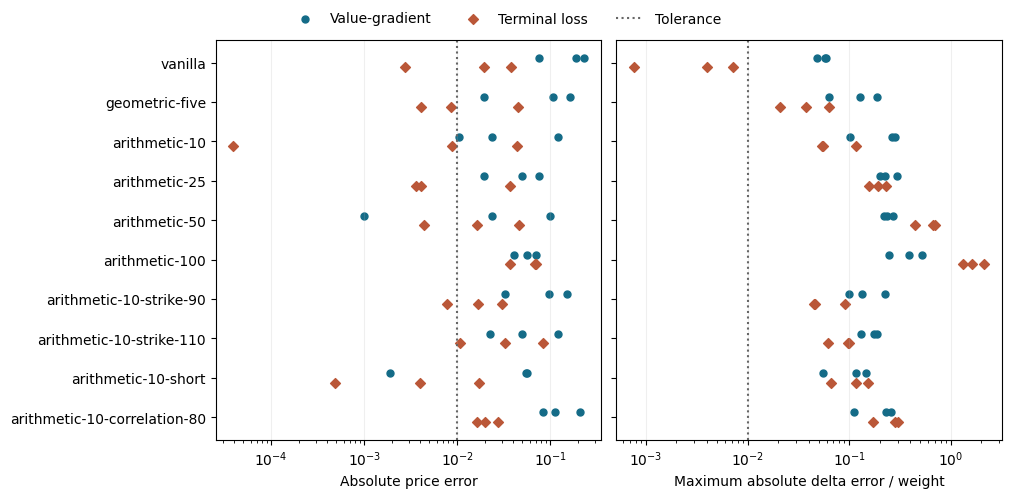

In [5]:
case_names = [row["name"] for row in spec["cases"]]
fig, axes = plt.subplots(1, 2, figsize=(10, 4.9), sharey=True, layout="constrained")
for solver, offset, marker in (("value_gradient", -0.12, "o"), ("terminal_loss", 0.12, "D")):
    group = [row for row in baseline if row["job"]["solver"] == solver]
    y = [case_names.index(row["job"]["case"]) + offset for row in group]
    price_errors = [abs(row["price_error"]) for row in group]
    delta_errors = [max(map(abs, row["scaled_delta_errors"])) for row in group]
    for ax, errors in zip(axes, (price_errors, delta_errors)):
        ax.scatter(errors, y, s=25, marker=marker, color=colors[solver], label=formulations[solver])
for ax, tolerance, label in zip(
    axes, (price_target, delta_target),
    ("Absolute price error", "Maximum absolute delta error / weight"),
):
    ax.axvline(tolerance, color="0.4", linestyle=":", label="Tolerance")
    ax.set(xscale="log", xlabel=label)
    ax.grid(axis="x", alpha=0.2)
axes[0].set_yticks(range(len(case_names)), case_names)
axes[0].invert_yaxis()
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside upper center", ncols=3, frameon=False)
plt.show()

At 100 assets all six absolute price errors exceed 0.01. The worst
scaled-coordinate errors reach 0.518 for value-gradient and 2.134 for
terminal loss. A price close to the reference can still accompany large
coordinate errors. At ten assets, the terminal fit with seed 41003 on
the base grid has an absolute price error of about 0.000039 and worst
scaled delta error of 0.1171.

### Ten-asset grid study

All grid rows share the contract and reference. The optimizer budget
is fixed. Adding intervals increases work per update, and the terminal
solver has one extra control network per extra interval.

In [6]:
rows = []
for steps in sorted([spec["training"]["base_steps"], *spec["grid_steps"]]):
    for solver, label in formulations.items():
        group = [row for row in completed_fits if row["job"]["case"] == spec["grid_case"]
                 and (row["job"]["n_steps"], row["job"]["solver"]) == (steps, solver)]
        price_errors = [abs(row["price_error"]) for row in group]
        scaled_error = max(abs(e) for row in group for e in row["scaled_delta_errors"])
        passes = sum(row["price_classification"] == "within_target" for row in group)
        joint = sum(row["accuracy"] == "within_target" for row in group)
        rows.append((steps, label, f"{group[0]['parameters']:,}", f"{min(price_errors):.4g}–{max(price_errors):.4g}",
                     f"{scaled_error:.4f}", f"{passes}/{len(group)}", f"{joint}/{len(group)}",
                     f"{median(row['training_seconds'] for row in group):.2f}"))
table(("Intervals", "Formulation", "Parameters", "Absolute price error range",
       "Worst scaled delta error", "Price passes", "Joint passes", "Median fit (s)"), rows)

| Intervals | Formulation | Parameters | Absolute price error range | Worst scaled delta error | Price passes | Joint passes | Median fit (s) |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 10 | Value-gradient | 481 | 0.01054–0.1033 | 0.2534 | 0/3 | 0/3 | 6.95 |
| 10 | Terminal loss | 5,573 | 0.009607–0.05962 | 0.1010 | 0/3 | 0/3 | 9.96 |
| 16 | Value-gradient | 481 | 0.01049–0.122 | 0.2860 | 0/3 | 0/3 | 9.15 |
| 16 | Terminal loss | 9,281 | 3.923e-05–0.0435 | 0.1171 | 2/3 | 0/3 | 16.16 |
| 20 | Value-gradient | 481 | 0.02498–0.182 | 0.2933 | 0/3 | 0/3 | 11.18 |
| 20 | Terminal loss | 11,753 | 0.001877–0.01111 | 0.0914 | 2/3 | 0/3 | 20.48 |
| 40 | Value-gradient | 481 | 0.00676–0.1047 | 0.3035 | 1/3 | 0/3 | 21.05 |
| 40 | Terminal loss | 24,113 | 0.005333–0.01705 | 0.1078 | 1/3 | 0/3 | 42.84 |

Six of the 24 fits passed on price. One price decision was unresolved,
and all 24 missed the joint target. Across the tested grids neither
formulation shows a monotone reduction in median price error. Changing
the integral approximation and the fitted architecture together limits
the interpretation to sensitivity under this budget.

## 4. Variance reduction and matched cost

A frozen predictable integrand gives
$I=\sum_j\widehat Z_j^\top\Delta W_j$ with
$\mathbb E[I\mid\text{fit}]=0$. Each increment has zero conditional mean
given the information at its left endpoint. If the coefficient $\beta$
is chosen on independent pilot draws, the evaluation average of
$X-\beta I$ has the same target as the discounted payoff $X$. The variance is

$$
\operatorname{Var}(X)-2\beta\,\operatorname{Cov}(X,I)+\beta^2\operatorname{Var}(I).
$$

For nonzero control variance, the minimizing coefficient is
$\operatorname{Cov}(X,I)/\operatorname{Var}(I)$. With antithetic paths,
$X$ and $I$ in this calculation are averages within pairs. A poor
integrand or a poorly chosen coefficient can raise the variance.

### Geometric martingale diagnostic

On the five-asset geometric call, the analytical delta gives an exact
continuous-time integrand. Evaluating it at left endpoints gives a
discrete martingale. The same paths are nested across the grids. The
mean of $I$ and the mean of
$I^2-\sum_j\|\widehat Z_j\|^2\Delta t_j$ are reported in standard-error
units. Both quantities have expectation zero.

In [7]:
known = run_known_control_study(geometric, n_paths=16_384, seed=2026, steps=(4, 8, 16, 32, 64))
table(("Intervals", "Controlled estimate", "SE", "Variance reduction", "Integral mean / SE", "Isometry gap / SE"), [
    (row["steps"], f"{row['analytical_control']['estimate']:.6f}",
     f"{row['analytical_control']['standard_error']:.6f}", f"{row['variance_reduction_factor']:.1f}×",
     f"{row['stochastic_integral']['mean_in_standard_errors']:+.2f}",
     f"{row['isometry_gap']['mean_in_standard_errors']:+.2f}")
    for row in known["grids"]
])

| Intervals | Controlled estimate | SE | Variance reduction | Integral mean / SE | Isometry gap / SE |
| --- | --- | --- | --- | --- | --- |
| 4 | 5.517769 | 0.019937 | 11.5× | -0.91 | -1.03 |
| 8 | 5.524709 | 0.014559 | 21.5× | -0.99 | -0.99 |
| 16 | 5.509509 | 0.010317 | 42.8× | -0.76 | -0.99 |
| 32 | 5.503657 | 0.007317 | 85.1× | -0.66 | -1.16 |
| 64 | 5.500169 | 0.005240 | 165.9× | -0.61 | -1.14 |

The exact geometric price is 5.494719. The variance reduction rises from
about 11 to 166 as the integrand grid refines. The eight-interval estimate
is 2.06 standard errors above the exact price. The integral means and
isometry gaps are within 1.2 standard errors of zero. Shared paths make
the grid results dependent.

### Arithmetic-basket benchmark

The base ten-asset contract uses 16 repetitions for each of three frozen
checkpoint pairs. The seven variants are two geometric terminal-payoff
controls, the analytical geometric integrand used as an arithmetic
proxy, and unit or pilot-fitted coefficients for each learned integrand.
The allocations match terminal states across methods. Martingale
estimators also evaluate all intermediate grid states.

A method qualifies at the smallest measured allocation with every
repetition at or below the target half-width. Pair averages and
independent scramble means supply the sampling units for antithetic and
Sobol methods respectively. Antithetic intervals use the normal
critical value and Sobol intervals use Student-$t$ across scrambles. The plot summarizes median interval widths.
The allocation decision uses all 16 observed widths in each seed cohort.

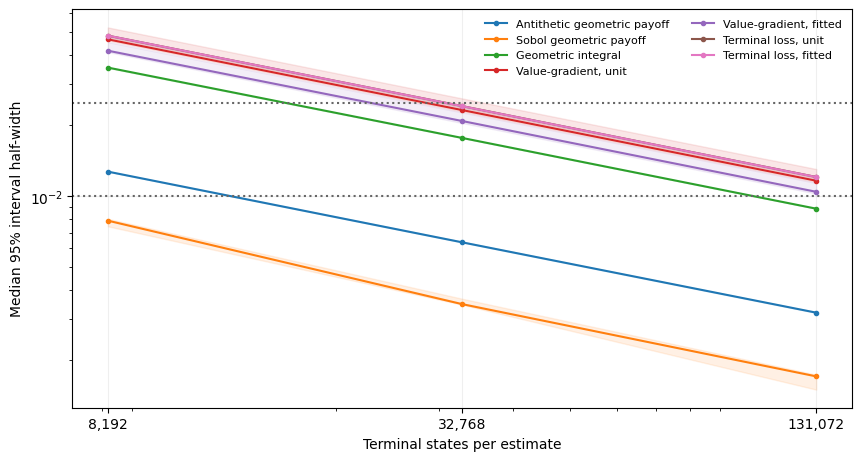

In [8]:
methods = {
    "antithetic_geometric_control": "Antithetic geometric payoff",
    "scrambled_sobol_geometric_control": "Sobol geometric payoff",
    "analytical_geometric_proxy_unit": "Geometric integral",
    "value_gradient_unit": "Value-gradient, unit",
    "value_gradient_fitted": "Value-gradient, fitted",
    "terminal_loss_unit": "Terminal loss, unit",
    "terminal_loss_fitted": "Terminal loss, fitted",
}
states = [2 * pairs for pairs in spec["estimators"]["antithetic_pairs"]]
fig, ax = plt.subplots(figsize=(8.5, 4.5), layout="constrained")
for method, label in methods.items():
    widths = np.asarray([[a["methods"][method]["median_half_width"] for a in row["allocations"]]
                         for row in cohorts.values()])
    line, = ax.loglog(states, np.median(widths, axis=0), marker=".", label=label)
    ax.fill_between(states, widths.min(axis=0), widths.max(axis=0), color=line.get_color(), alpha=0.11)
for target in (0.025, 0.01):
    ax.axhline(target, linestyle=":", color="0.4")
ax.set_xticks(states, [f"{n:,}" for n in states])
ax.set(xlabel="Terminal states per estimate", ylabel="Median 95% interval half-width")
ax.legend(fontsize=8, ncols=2, frameon=False)
ax.grid(alpha=0.2)
plt.show()

The bands span the three cohort medians. The conventional payoff controls
produce smaller intervals across the measured budgets. A low median alone
cannot establish that all repetitions qualify.

### Total cost and break-even

The per-cohort cost model for $q$ fresh estimates of the fixed contract is
$C(q)=C_{\rm fit}+C_{\rm load}+C_{\rm pilot}+qC_{\rm eval}$.
Applicable setup and evaluation times are measured within each cohort.
The fit and coefficient can be reused. A sustained cost advantage requires
lower marginal cost, or equal marginal cost and no larger upfront charge.

The table shows the selected allocations across qualifying cohorts
and the median total cost over those cohorts. A dash denotes a precision
target missed in every cohort.

In [9]:
rows = []
cost_100 = {}
for target in ("0.025", "0.01"):
    for method, label in methods.items():
        matches = [cohort["matched_precision"][target][method] for cohort in cohorts.values()]
        eligible = [row for row in matches if row["status"] == "target_met"]
        allocations = ", ".join(f"{n:,}" for n in sorted({row["evaluation_states"] for row in eligible}))
        costs = [median(row["total_seconds"][q] for row in eligible) for q in ("1", "100")] if eligible else []
        shown_costs = [f"{value:.4f}" for value in costs] if eligible else ["—", "—"]
        break_even = sum(any(q is not None for q in row.get("break_even_queries", {}).values())
                         for row in eligible)
        rows.append((target, label, f"{len(eligible)}/{len(matches)}", allocations or "—",
                     *shown_costs, "—" if not eligible or method.endswith("geometric_control") else break_even))
        if target == "0.025" and eligible:
            cost_100[method] = costs[1]
table(("Half-width", "Method", "Qualifying cohorts", "Terminal states",
       "Median cost, 1 (s)", "Median cost, 100 (s)", "Cohorts with break-even"), rows)

| Half-width | Method | Qualifying cohorts | Terminal states | Median cost, 1 (s) | Median cost, 100 (s) | Cohorts with break-even |
| --- | --- | --- | --- | --- | --- | --- |
| 0.025 | Antithetic geometric payoff | 3/3 | 8,192 | 0.0032 | 0.1417 | — |
| 0.025 | Sobol geometric payoff | 3/3 | 8,192 | 0.0319 | 3.0171 | — |
| 0.025 | Geometric integral | 3/3 | 32,768 | 0.5379 | 53.7900 | 0 |
| 0.025 | Value-gradient, unit | 3/3 | 32,768, 131,072 | 10.8193 | 115.1119 | 0 |
| 0.025 | Value-gradient, fitted | 3/3 | 32,768 | 10.4806 | 114.5810 | 0 |
| 0.025 | Terminal loss, unit | 3/3 | 32,768 | 16.6881 | 68.3632 | 0 |
| 0.025 | Terminal loss, fitted | 3/3 | 32,768 | 16.8196 | 68.4948 | 0 |
| 0.01 | Antithetic geometric payoff | 3/3 | 32,768 | 0.0077 | 0.5960 | — |
| 0.01 | Sobol geometric payoff | 3/3 | 8,192, 32,768 | 0.0268 | 2.5056 | — |
| 0.01 | Geometric integral | 3/3 | 131,072 | 2.1685 | 216.8504 | 0 |
| 0.01 | Value-gradient, unit | 0/3 | — | — | — | — |
| 0.01 | Value-gradient, fitted | 0/3 | — | — | — | — |
| 0.01 | Terminal loss, unit | 0/3 | — | — | — | — |
| 0.01 | Terminal loss, fitted | 0/3 | — | — | — | — |

At 0.025, both conventional controls qualify at 8,192 states in every
cohort. The learned controls require at least 32,768 states and cost more
per query. No martingale variant reaches sustained break-even against a
qualified conventional comparator. At 0.01, both conventional controls
and the geometric integral qualify in every cohort. Every learned
variant misses the tighter target.

The 100-query median costs on the Mac are 0.14 seconds for the antithetic
payoff control and 68.36 seconds for the cheapest learned variant.
The difference persists after training is spread across the repeated
queries. Mean preservation and time per estimate are separate properties.

## 5. Findings and scope

Initial prices and spot sensitivities answer different validation questions.
One fit passed the joint gate. Six ten-asset grid fits passed price alone,
and the tested grid refinements showed no consistent accuracy improvement
under a fixed training budget. The learned controls preserved the model
price as their estimator target. For the measured ten-asset contract the
direct geometric-payoff controls met the same half-width target at lower
total and marginal cost.

The paired panels below summarize all 78 initial fits and the 100-query
cost at half-width 0.025. The point-error lines in the left panel are
visual guides. Formal fit classifications incorporate numerical-reference
uncertainty. Timing describes repeated estimates of a single contract
on the recorded platform.

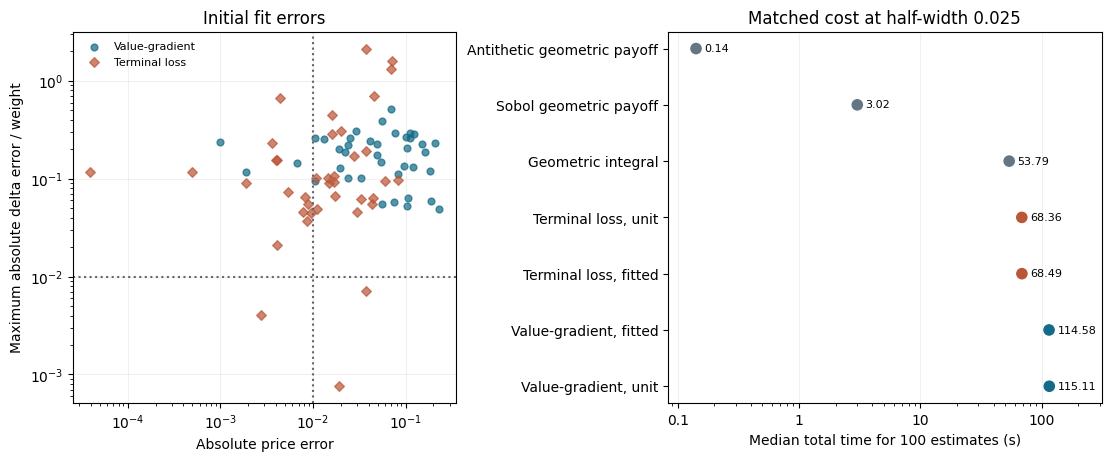

In [10]:
fig, (ax_error, ax_cost) = plt.subplots(
    1, 2, figsize=(11, 4.5), gridspec_kw={"width_ratios": [1, 1.13]}, layout="constrained",
)
for solver, marker in (("value_gradient", "o"), ("terminal_loss", "D")):
    group = [row for row in completed_fits if row["job"]["solver"] == solver]
    ax_error.scatter([abs(row["price_error"]) for row in group],
                     [max(map(abs, row["scaled_delta_errors"])) for row in group],
                     s=24, alpha=0.72, marker=marker, color=colors[solver], label=formulations[solver])
ax_error.axvline(price_target, color="0.4", linestyle=":")
ax_error.axhline(delta_target, color="0.4", linestyle=":")
ax_error.set(xscale="log", yscale="log", xlabel="Absolute price error",
             ylabel="Maximum absolute delta error / weight", title="Initial fit errors")
ax_error.legend(loc="upper left", frameon=False, fontsize=8)
ax_error.grid(alpha=0.18)

order = sorted(cost_100, key=cost_100.get)
values = [cost_100[method] for method in order]
bar_colors = [colors.get(method.rsplit("_", 1)[0], "#647583") for method in order]
positions = np.arange(len(order))
ax_cost.scatter(values, positions, color=bar_colors, s=54, zorder=3)
ax_cost.set_yticks(positions, [methods[method] for method in order])
for position, value in zip(positions, values):
    ax_cost.annotate(f"{value:.2f}", (value, position), xytext=(6, 0),
                     textcoords="offset points", va="center", fontsize=8)
ax_cost.set(xscale="log", xlim=(min(values) / 1.7, max(values) * 2.7),
            xlabel="Median total time for 100 estimates (s)", title="Matched cost at half-width 0.025")
ax_cost.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:g}"))
ax_cost.invert_yaxis()
ax_cost.grid(axis="x", alpha=0.18)
plt.show()

### Reproduction

The [report](../docs/report.md) develops the derivations and summarizes the
assumptions behind the convergence discussion. Run the locked design from the
repository root in the environment defined by [environment.yml](../environment.yml).

~~~sh
python -m bsde_pricing experiment-design
python -m bsde_pricing final-suite --run-dir scratch/runs/final_suite
python -m experiments.summarize scratch/runs/final_suite/report.json scratch/runs/final_suite/summary.json
~~~

The completed ledger identifies the specification, source and environment.
The checked-in result file retains the Apple silicon run used above. The
final paired-panel cell generates the figure shared by the README and report.